# Gold lesen als ML-Anwendung

Diese ML-Anwendung ist nicht direkt Teil der Aufgabenstellung. Sie dient als Validierung und
Proof of Concept dafür, dass die Pipeline die Daten tatsächlich in einer zugreifbaren Form
bereitstellt. Sie liest die Features aus `gold` mit der Identität `ml_reader`, die nur `gold`
lesen darf. Voraussetzung: ein abgeschlossener Lauf (`docker compose up`), SeaweedFS unter
`http://localhost:8333`.

```sh
uv sync --directory ml_reader
uv run --directory ml_reader --env-file ../.env jupyter nbconvert --execute --to notebook --inplace gold_analysis.ipynb
```

Interaktiv: Kernel `ml_reader/.venv` wählen und `S3_ML_ACCESS_KEY`/`S3_ML_SECRET_KEY`
setzen.

In [37]:
import os

import pandas as pd
from pyarrow import fs

endpoint = os.environ.get("S3_ENDPOINT", "localhost:8333")
s3 = fs.S3FileSystem(
    access_key=os.environ["S3_ML_ACCESS_KEY"],
    secret_key=os.environ["S3_ML_SECRET_KEY"],
    endpoint_override=endpoint,
    scheme="http",
)
try:
    s3.get_file_info("gold")
except OSError as e:
    raise ConnectionError(
        f"Kein Zugriff auf SeaweedFS unter {endpoint}. Läuft der Stack (docker compose up)? "
        "Stimmen S3_ML_ACCESS_KEY/S3_ML_SECRET_KEY?"
    ) from e

## Features laden

Eine Zeile je Pickup-Zone und Stunde, partitioniert nach `year=YYYY/month=MM`.

In [38]:
gold = pd.read_parquet("gold/yellow_tripdata/zone_hourly", filesystem=s3)
print(f"{len(gold):,} Zeilen, {gold['trip_count'].sum():,} Fahrten")
gold.groupby(["year", "month"]).agg(rows=("trip_count", "size"), trips=("trip_count", "sum"))

240,710 Zeilen, 9,417,422 Fahrten


rows    trips
year month                
2024 1      77484  2926937
     2      74330  2966714
     3      88896  3523771

In [27]:
gold

,pickup_hour,pu_location_id,trip_count,avg_trip_distance,avg_duration_minutes,avg_fare_amount,avg_total_amount,hour_of_day,day_of_week,is_weekend,_processed_at,year,month
0,2024-01-03 07:00:00,142,74,2.199595,9.948423,12.759459,19.367973,7,3,False,2026-10-31 23:53:58.405435,2024,1
1,2024-01-03 07:00:00,132,230,14.306826,52.525507,60.916522,75.787391,7,3,False,2026-10-31 23:53:58.405435,2024,1
2,2024-01-04 19:00:00,137,66,2.485455,12.074747,14.441364,23.951061,19,4,False,2026-10-31 23:53:58.405435,2024,1
3,2024-01-05 00:00:00,114,85,2.377294,10.963922,13.541176,21.529412,0,5,False,2026-10-31 23:53:58.405435,2024,1
4,2024-01-05 19:00:00,48,159,2.071321,20.987421,13.817358,23.313396,19,5,False,2026-10-31 23:53:58.405435,2024,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
240705,2024-03-16 13:00:00,28,1,0.000000,11.816667,10.000000,11.500000,13,6,True,2026-10-31 23:54:09.475313,2024,3
240706,2024-03-30 07:00:00,72,1,1.890000,7.766667,10.020000,11.520000,7,6,True,2026-10-31 23:54:09.475313,2024,3
240707,2024-03-23 18:00:00,217,1,2.650000,19.833333,19.870000,23.870000,18,6,True,2026-10-31 23:54:09.475313,2024,3
240708,2024-03-06 18:00:00,81,1,2.100000,40.066667,25.500000,27.000000,18,3,False,2026-10-31 23:54:09.475313,2024,3


## Aktualität

Der Laufbericht zeigt, wann Gold je Monat zuletzt geschrieben wurde.

In [28]:
reports = [
    f.path
    for f in s3.get_file_info(fs.FileSelector("gold/_reports", recursive=True))
    if f.path.endswith(".json")
]
pd.concat(pd.read_json(s3.open_input_stream(p), lines=True) for p in reports)[
    ["month", "gold_trips", "gold_processed_at"]
].sort_values("month")

,month,gold_trips,gold_processed_at
0,2024-01,2926937,2026-10-31 23:53:58.405+00:00
1,2024-02,2966714,2026-10-31 23:54:06.144+00:00
2,2024-03,3523771,2026-10-31 23:54:09.475+00:00


## Einfache Analyse

In [29]:
gold.groupby("pu_location_id")["trip_count"].sum().nlargest(10).rename("trips").to_frame()

,trips
pu_location_id,
161,447795
237,434214
132,416433
236,412390
162,332215
230,325683
186,315488
142,312342
138,281280


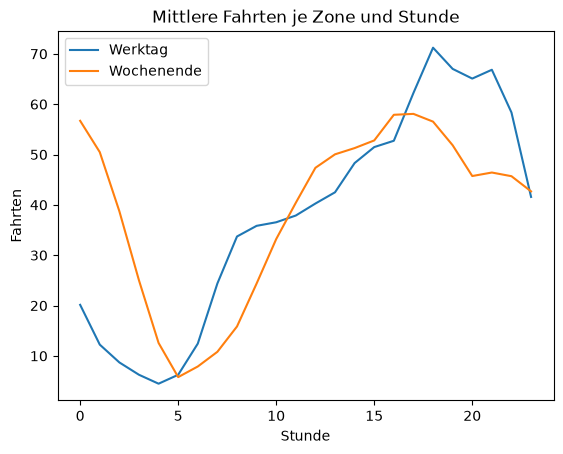

In [30]:
by_hour = gold.groupby(["is_weekend", "hour_of_day"])["trip_count"].mean().unstack(0)
by_hour.columns = ["Werktag", "Wochenende"]
ax = by_hour.plot(title="Mittlere Fahrten je Zone und Stunde", xlabel="Stunde", ylabel="Fahrten")

In [31]:
gold[["trip_count", "avg_trip_distance", "avg_duration_minutes", "avg_fare_amount"]].describe()

,trip_count,avg_trip_distance,avg_duration_minutes,avg_fare_amount
count,240710.000000,240710.000000,240710.000000,240710.000000
mean,39.123518,4.532614,21.984062,25.643502
std,73.014851,4.312422,24.140740,19.678362
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,2.010000,11.330952,14.535000
50%,4.000000,2.851056,15.366667,19.195000
75%,41.000000,5.646667,25.283333,31.475000
max,835.000000,120.780000,1439.800000,949.500000


## Zugriffsrechte

`ml_reader` darf Silver nicht lesen; der Versuch muss scheitern.

In [32]:
try:
    pd.read_parquet("silver/yellow_tripdata", filesystem=s3)
    print("Unerwartet: Silver lesbar")
except OSError as e:
    print("Erwartet abgelehnt:", e)

Erwartet abgelehnt: When getting information for key 'yellow_tripdata' in bucket 'silver': AWS Error ACCESS_DENIED during HeadObject operation: No response body.
